In [4]:
import torch
import torchvision
from torchvision.transforms import v2

In [7]:
!pip -q install datasets
import torch
import torchvision
from torch.utils.data import Subset, DataLoader
from torchvision.transforms import v2
from datasets import load_dataset

# Preprocessing
norm = v2.Normalize((0.5,)*3, (0.5,)*3)
train_tf = v2.Compose([v2.ToImage(), v2.RandomCrop(32, padding=4),
                       v2.RandomHorizontalFlip(),
                       v2.ToDtype(torch.float32, scale=True), norm])
test_tf  = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True), norm])

# Known vs unknown classes
KNOWN   = [0, 1, 2, 3, 4, 5]   # plane car bird cat deer dog
UNKNOWN = [6, 7, 8, 9]         # frog horse ship truck
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog')
remap = {old: new for new, old in enumerate(KNOWN)}

# Dataset from Hugging Face
hf = load_dataset("uoft-cs/cifar10")

class HFCifar(torch.utils.data.Dataset):
    def __init__(self, split, transform, target_transform):
        self.ds = hf[split]
        self.targets = list(self.ds["label"])
        self.transform, self.target_transform = transform, target_transform
    def __len__(self):
        return len(self.ds)
    def __getitem__(self, i):
        ex = self.ds[i]
        return self.transform(ex["img"]), self.target_transform(ex["label"])

train_full = HFCifar("train", train_tf, lambda y: remap.get(y, -1))
test_full  = HFCifar("test",  test_tf,  lambda y: remap.get(y, -1))

# Split and loaders
def idx(ds, keep):
    return [i for i, y in enumerate(ds.targets) if y in keep]

trainset     = Subset(train_full, idx(train_full, KNOWN))
test_known   = Subset(test_full,  idx(test_full,  KNOWN))
test_unknown = Subset(test_full,  idx(test_full,  UNKNOWN))  # never seen in training

batch_size = 64
trainloader   = DataLoader(trainset,     batch_size, shuffle=True,  num_workers=2)
knownloader   = DataLoader(test_known,   batch_size, shuffle=False, num_workers=2)
unknownloader = DataLoader(test_unknown, batch_size, shuffle=False, num_workers=2)

print(len(trainset), len(test_known), len(test_unknown))  # expect 30000 6000 4000

30000 6000 4000


In [8]:
def idx(ds, keep):
    return [i for i, y in enumerate(ds.targets) if y in keep]

trainset     = Subset(train_full, idx(train_full, KNOWN))
test_known   = Subset(test_full,  idx(test_full,  KNOWN))
test_unknown = Subset(test_full,  idx(test_full,  UNKNOWN))  # never seen in training

batch_size = 64
trainloader   = DataLoader(trainset,     batch_size, shuffle=True,  num_workers=2)
knownloader   = DataLoader(test_known,   batch_size, shuffle=False, num_workers=2)
unknownloader = DataLoader(test_unknown, batch_size, shuffle=False, num_workers=2)

print(len(trainset), len(test_known), len(test_unknown))  # expect 30000 6000 4000

30000 6000 4000


In [9]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('using', device)

class Net(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.drop  = nn.Dropout(0.3)
        self.fc1   = nn.Linear(128 * 4 * 4, 256)
        self.fc2   = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 32 -> 16
        x = self.pool(F.relu(self.conv2(x)))   # 16 -> 8
        x = self.pool(F.relu(self.conv3(x)))   # 8 -> 4
        x = torch.flatten(x, 1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)                     # raw logits

net = Net().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=1e-3)
EPOCHS = 15

for epoch in range(EPOCHS):
    net.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    print(f'epoch {epoch+1}: loss {running_loss/total:.3f}, train acc {correct/total:.3f}')

torch.save(net.state_dict(), 'model.pth')

net.eval()
correct, total = 0, 0
with torch.no_grad():
    for inputs, labels in knownloader:
        inputs, labels = inputs.to(device), labels.to(device)
        correct += (net(inputs).argmax(1) == labels).sum().item()
        total += labels.size(0)
print(f'Known-class test accuracy: {correct/total:.3f}')

using cuda
epoch 1: loss 1.279, train acc 0.471
epoch 2: loss 1.056, train acc 0.572
epoch 3: loss 0.931, train acc 0.633
epoch 4: loss 0.832, train acc 0.678
epoch 5: loss 0.771, train acc 0.705
epoch 6: loss 0.726, train acc 0.725
epoch 7: loss 0.689, train acc 0.742
epoch 8: loss 0.669, train acc 0.749
epoch 9: loss 0.629, train acc 0.763
epoch 10: loss 0.608, train acc 0.771
epoch 11: loss 0.585, train acc 0.780
epoch 12: loss 0.577, train acc 0.783
epoch 13: loss 0.548, train acc 0.796
epoch 14: loss 0.543, train acc 0.797
epoch 15: loss 0.524, train acc 0.803
Known-class test accuracy: 0.807


In [10]:
import numpy as np
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

@torch.no_grad()
def get_logits(loader):
    net.eval()
    out, ys = [], []
    for x, y in loader:
        out.append(net(x.to(device)).cpu())
        ys.append(y)
    return torch.cat(out), torch.cat(ys).numpy()

logits_k, labels_k = get_logits(knownloader)
logits_u, _        = get_logits(unknownloader)
preds_k   = logits_k.argmax(1).numpy()
correct_k = preds_k == labels_k
N = len(logits_k) + len(logits_u)

# Confidence scores: higher means "looks like a known class"
def msp(logits):    return F.softmax(logits, 1).max(1).values.numpy()   # max softmax probability
def energy(logits): return torch.logsumexp(logits, 1).numpy()           # negative energy score

def report(name, score_fn):
    s_k, s_u = score_fn(logits_k), score_fn(logits_u)
    thr = np.percentile(s_k, 5)                  # keeps 95% of known images
    auroc = roc_auc_score(np.r_[np.ones(len(s_k)), np.zeros(len(s_u))], np.r_[s_k, s_u])
    keep_k, keep_u = s_k >= thr, s_u >= thr
    open_acc = ((correct_k & keep_k).sum() + (~keep_u).sum()) / N
    print(f'{name:7s} AUROC {auroc:.3f} | FPR@95 {keep_u.mean():.3f} | '
          f'acc on accepted known {correct_k[keep_k].mean():.3f} | open-set acc {open_acc:.3f}')
    return s_k, s_u, thr

print(f'No rejection: known acc {correct_k.mean():.3f} | open-set acc {correct_k.sum()/N:.3f}')
msp_k, msp_u, msp_thr = report('MSP', msp)
en_k,  en_u,  en_thr  = report('Energy', energy)

No rejection: known acc 0.807 | open-set acc 0.484
MSP     AUROC 0.624 | FPR@95 0.901 | acc on accepted known 0.834 | open-set acc 0.515
Energy  AUROC 0.666 | FPR@95 0.856 | acc on accepted known 0.829 | open-set acc 0.530


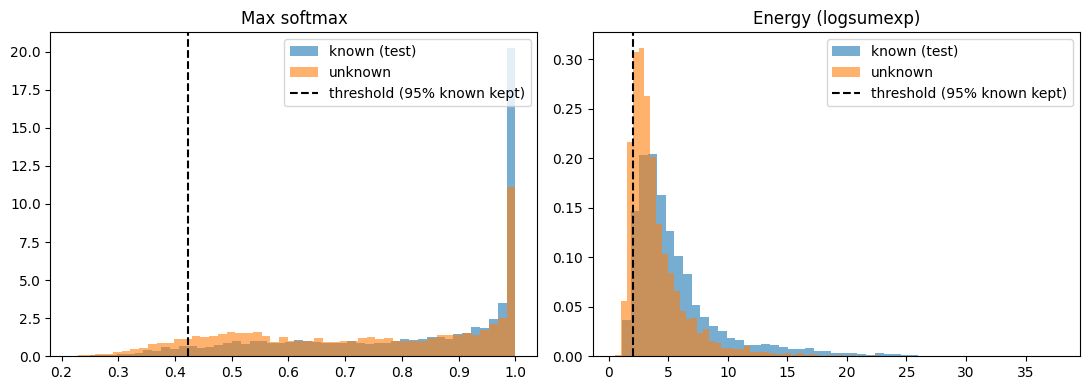

In [11]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, sk, su, t) in zip(axes, [('Max softmax', msp_k, msp_u, msp_thr),
                                        ('Energy (logsumexp)', en_k, en_u, en_thr)]):
    ax.hist(sk, bins=50, alpha=0.6, density=True, label='known (test)')
    ax.hist(su, bins=50, alpha=0.6, density=True, label='unknown')
    ax.axvline(t, color='k', ls='--', label='threshold (95% known kept)')
    ax.set_title(name); ax.legend()
plt.tight_layout(); plt.savefig('score_hist.png', dpi=120); plt.show()

frog   accepted: MSP 0.86  Energy 0.84
horse  accepted: MSP 0.84  Energy 0.85
ship   accepted: MSP 0.95  Energy 0.86
truck  accepted: MSP 0.95  Energy 0.87
predicted as  bird   car   cat  deer   dog  plane
unknown                                          
frog          0.24  0.02  0.36  0.32  0.04   0.02
horse         0.11  0.01  0.13  0.44  0.24   0.06
ship          0.06  0.17  0.06  0.03  0.01   0.67
truck         0.02  0.71  0.05  0.01  0.02   0.17


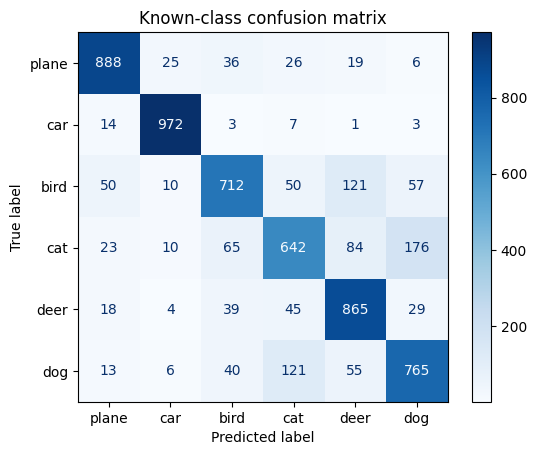

mean MSP  correct known 0.866 | wrong known 0.602 | unknown 0.729


In [12]:
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

names10 = ('plane','car','bird','cat','deer','dog','frog','horse','ship','truck')
orig_u  = np.array([test_full.targets[i] for i in test_unknown.indices])  # real labels of unknowns
preds_u = logits_u.argmax(1).numpy()

# 1. How often each unknown class slips past the detector
for c in UNKNOWN:
    m = orig_u == c
    print(f'{names10[c]:6s} accepted: MSP {(msp_u[m] >= msp_thr).mean():.2f}  Energy {(en_u[m] >= en_thr).mean():.2f}')

# 2. What each unknown class gets mistaken for
print(pd.crosstab(np.array(names10)[orig_u], np.array(classes)[preds_u],
                  rownames=['unknown'], colnames=['predicted as'], normalize='index').round(2))

# 3. Where the classifier itself is wrong on known classes
ConfusionMatrixDisplay(confusion_matrix(labels_k, preds_k), display_labels=classes).plot(cmap='Blues')
plt.title('Known-class confusion matrix'); plt.savefig('confusion.png', dpi=120); plt.show()

# 4. Is the model less confident when it is wrong?
print(f'mean MSP  correct known {msp_k[correct_k].mean():.3f} | '
      f'wrong known {msp_k[~correct_k].mean():.3f} | unknown {msp_u.mean():.3f}')

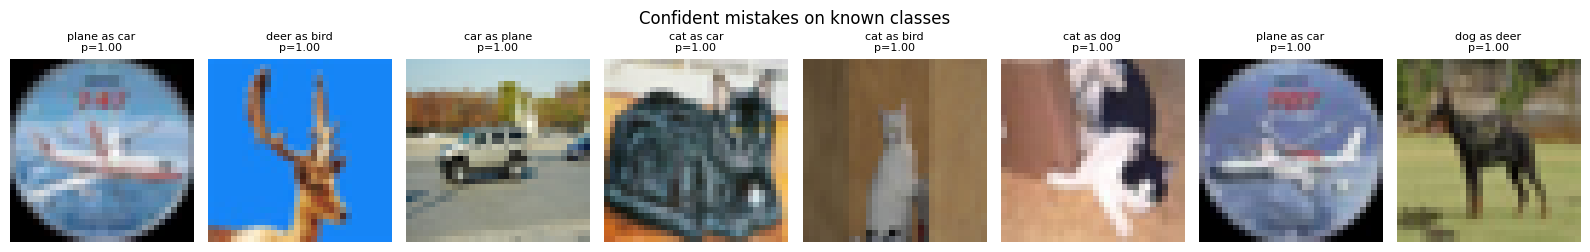

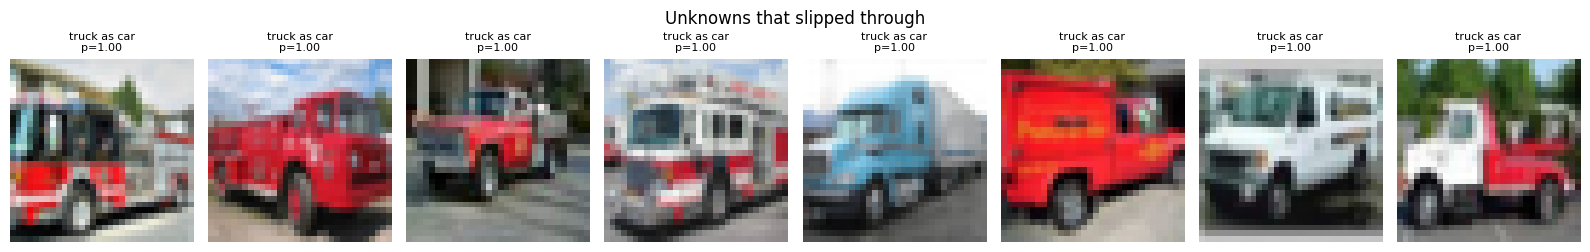

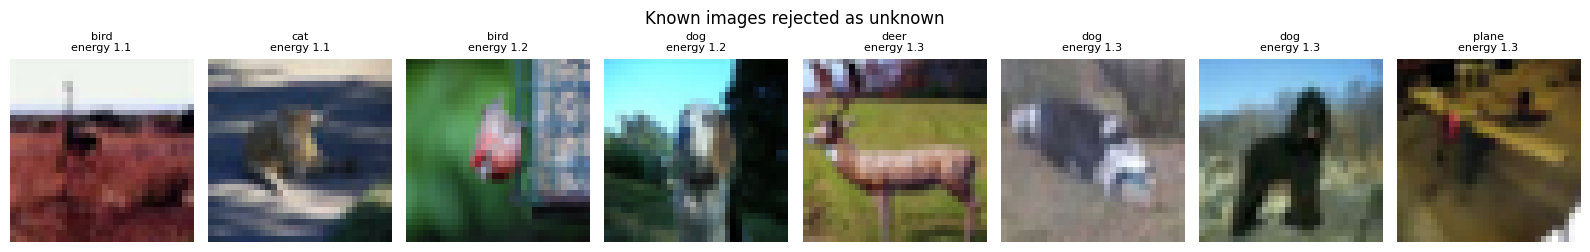

In [13]:
def show(ds, idxs, titles, suptitle, fname):
    fig, axes = plt.subplots(1, len(idxs), figsize=(2 * len(idxs), 2.6))
    for ax, i, t in zip(axes, idxs, titles):
        img = (ds[i][0] * 0.5 + 0.5).permute(1, 2, 0).clamp(0, 1).numpy()  # undo Normalize
        ax.imshow(img); ax.set_title(t, fontsize=8); ax.axis('off')
    fig.suptitle(suptitle); plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()

# a) Known images the model got wrong with high confidence
wrong = np.where(~correct_k)[0]
top = wrong[np.argsort(-msp_k[wrong])][:8]
show(test_known, top, [f'{classes[labels_k[i]]} as {classes[preds_k[i]]}\np={msp_k[i]:.2f}' for i in top],
     'Confident mistakes on known classes', 'fail_confident_wrong.png')

# b) Unknowns the detector accepted most confidently
top = np.argsort(-en_u)[:8]
show(test_unknown, top, [f'{names10[orig_u[i]]} as {classes[preds_u[i]]}\np={msp_u[i]:.2f}' for i in top],
     'Unknowns that slipped through', 'fail_unknown_accepted.png')

# c) Known images wrongly rejected as unknown
rej = np.where(en_k < en_thr)[0]
top = rej[np.argsort(en_k[rej])][:8]
show(test_known, top, [f'{classes[labels_k[i]]}\nenergy {en_k[i]:.1f}' for i in top],
     'Known images rejected as unknown', 'fail_known_rejected.png')

In [14]:
!zip -q plots.zip *.png model.pth
from google.colab import files
files.download('plots.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>